# Customer Churn Prediction & Retention Intelligence Platform
## Phase 1: Data Understanding, Quality Audit, EDA, Feature Pipeline & Modeler Handoff

### 1. Project Overview & Business Problem
* **Business Context:** في شركات التجارة الإلكترونية (E-commerce)، تكلفة اكتساب عميل جديد (Customer Acquisition Cost) تفوق بكثير تكلفة الحفاظ على العملاء الحاليين. الهدف هو بناء منصة تنبؤية للتعرف الاستباقي على العملاء المعرضين لخطر ترك المتجر (Churn Risk) لمساعدة فريق التسويق والاحتفاظ (Retention Team) على التدخل المبكر.
* **Data Source:** بيانات معاملات متجر `Online Retail II` مجمعة في لقطات زمنية ربع سنوية (Quarterly Snapshots).
* **Operational Churn Definition:** نظراً لعدم وجود اشتراك صريح، تم تعريف الـ Churn تشغيلياً (`churn = 1`) بأن العميل لم يقم بأي عملية شراء على الإطلاق خلال الـ 90 يوماً التالية لتاريخ اللقطة (Snapshot).
* **Scope of this Notebook:**
  1. التحقق الشامل من جودة البيانات (Missing Values, Duplicates, Invalid Values).
  2. فحص تسريب البيانات (Target & Temporal Leakage Audit).
  3. التحليل الاستكشافي المعمق (EDA) وفهم سلوكيات العملاء.
  4. فصل الـ Metadata وهندسة الخصائص (Feature Engineering).
  5. بناء استراتيجية تقسيم زمني متطورة (Temporal Train / Validation / Test Split).
  6. بناء وحفظ Preprocessing Pipeline قابل لإعادة الاستخدام بدون أي تسريب.
  7. تصدير ملفات البيانات ووثيقة التسليم (Modeler Handoff Document) ومصفوفة المفردات (Data Dictionary).


### 2. Environment Setup & Library Imports
في هذا الجزء نقوم باستدعاء المكتبات الأساسية لمعالجة البيانات، التحليل الإحصائي، الرسوم البيانية، وبناء الـ Preprocessing Pipeline من Scikit-Learn.


In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

# Data manipulation and numerical operations
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Machine Learning Pipeline tools
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import joblib

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Environment setup completed successfully!")
print(f"Pandas Version: {pd.__version__} | NumPy Version: {np.__version__}")


Environment setup completed successfully!
Pandas Version: 3.0.5 | NumPy Version: 2.5.2


### 3. Data Loading & Initial Schema Inspection
نقوم بقراءة ملف `churn_dataset.csv` والاطلاع على أبعاد البيانات (Shape)، وأنواع البيانات (Data Types)، ومعاينة الصفوف الأولى.


In [2]:
file_path = 'churn_dataset.csv'
df = pd.read_csv(file_path)

print(f"Dataset Shape: {df.shape[0]:,} rows and {df.shape[1]} columns\n")
print("--- Column Data Types & Non-Null Summary ---")
display(df.dtypes.to_frame(name='Data Type'))
display(df.head())


Dataset Shape: 22,372 rows and 26 columns

--- Column Data Types & Non-Null Summary ---


,Data Type
Customer ID,int64
snapshot,str
split,str
recency,float64
frequency,int64
monetary,float64
avg_order_value,float64
std_order_value,float64
tenure,float64
avg_days_between_orders,float64


,Customer ID,snapshot,split,recency,frequency,monetary,avg_order_value,std_order_value,tenure,avg_days_between_orders,std_days_between_orders,recency_to_gap_ratio,is_single_order,n_unique_products,avg_basket_size,avg_unit_price,return_rate,orders_last_30d,orders_last_60d,orders_last_90d,spend_last_90d,spend_trend,frequency_trend,is_uk,weekend_share,churn
0,12346,2010-09-09,train,72.4215,2,169.3600,84.6800,81.5011,190.4528,118.0312,0.0000,0.6136,0,24,12.0000,7.0567,0.0000,0.0000,0.0000,1.0000,142.3100,1.0000,1.0000,1,0.0000,1
1,12349,2010-09-09,train,132.4444,1,1068.5200,1068.5200,0.0000,132.4444,47.0028,0.0000,2.8178,1,46,473.0000,4.2300,0.0226,0.0000,0.0000,0.0000,0.0000,-1.0000,-1.0000,0,0.0000,0
2,12355,2010-09-09,train,110.5007,1,488.2100,488.2100,0.0000,110.5007,47.0028,0.0000,2.3509,1,22,303.0000,2.3991,0.0000,0.0000,0.0000,0.0000,0.0000,-1.0000,-1.0000,0,0.0000,1
3,12358,2010-09-09,train,93.4806,2,1697.9300,848.9650,821.4672,274.6674,181.1868,0.0000,0.5159,0,34,295.0000,3.4426,0.0000,0.0000,0.0000,0.0000,0.0000,-1.0000,-1.0000,0,0.0000,0
4,12359,2010-09-09,train,78.5667,5,2012.0300,402.4060,249.2605,277.4361,49.7174,42.5828,1.5803,0,82,175.4000,5.1703,0.0467,0.0000,0.0000,1.0000,489.8000,0.1726,0.0000,0,0.3721,0


### 4. Data Quality & Cleaning Audit
فحص شامل للقيم المفقودة (Missing Values)، السجلات المكررة (Duplicates)، والتأكد من عدم تكرار العميل في نفس التاريخ، وفحص القيم الصفرية والسالبة وغير المنطقية.


In [3]:
print("="*60)
print("1. Missing Values (Null) Check:")
null_counts = df.isnull().sum()
if null_counts.sum() == 0:
    print(">> EXCELLENT: No missing values found across all 26 columns!")
else:
    display(null_counts[null_counts > 0])

print("\n" + "="*60)
print("2. Duplicate Records Check:")
exact_dups = df.duplicated().sum()
cust_snap_dups = df.duplicated(subset=['Customer ID', 'snapshot']).sum()
print(f"- Exact duplicate rows across all columns: {exact_dups}")
print(f"- Duplicate customer entries within the same snapshot: {cust_snap_dups}")

print("\n" + "="*60)
print("3. Value Range & Negative Values Check:")
num_cols = df.select_dtypes(include=[np.number]).columns.drop(['Customer ID', 'churn', 'is_uk', 'is_single_order'])
neg_features = {col: (df[col] < 0).sum() for col in num_cols if (df[col] < 0).sum() > 0}
print(f"Features containing negative values: {list(neg_features.keys())}")
for f, cnt in neg_features.items():
    print(f"  - {f}: {cnt:,} negative values (Min: {df[f].min():.4f}, Max: {df[f].max():.4f})")
print(">> NOTE: Negative values in 'spend_trend' and 'frequency_trend' are valid indicators of declining customer activity.")

print("\n" + "="*60)
print("4. Summary Statistics of Numerical Features:")
summary_table = df[num_cols].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
summary_table.rename(columns={'50%': 'median'}, inplace=True)
display(summary_table)


1. Missing Values (Null) Check:
>> EXCELLENT: No missing values found across all 26 columns!

2. Duplicate Records Check:
- Exact duplicate rows across all columns: 0
- Duplicate customer entries within the same snapshot: 0

3. Value Range & Negative Values Check:
Features containing negative values: ['spend_trend', 'frequency_trend']
  - spend_trend: 7,750 negative values (Min: -1.0000, Max: 1.0000)
  - frequency_trend: 6,587 negative values (Min: -1.0000, Max: 1.0000)
>> NOTE: Negative values in 'spend_trend' and 'frequency_trend' are valid indicators of declining customer activity.

4. Summary Statistics of Numerical Features:


,mean,std,min,25%,median,75%,max
recency,145.7391,137.9192,0.1681,33.4910,103.4653,222.4814,646.5493
frequency,4.8661,9.2367,1.0000,1.0000,2.0000,5.0000,284.0000
monetary,2216.7689,10047.8389,1.5500,305.3550,705.1250,1792.0500,456780.4900
avg_order_value,371.5653,577.8354,1.5500,175.2375,280.8650,414.4234,25784.3200
std_order_value,145.0372,635.7237,0.0000,0.0000,64.0578,164.4759,44513.1195
tenure,311.7774,168.1071,0.3000,183.3309,301.5628,448.3568,646.6771
avg_days_between_orders,71.2779,57.9937,0.0007,43.9696,56.2720,75.9882,632.1201
std_days_between_orders,24.0343,38.1990,0.0000,0.0000,0.0000,36.0796,440.4927
recency_to_gap_ratio,6.7677,34.5119,0.0014,0.5486,1.6070,4.0959,646.4493
n_unique_products,66.9621,92.8047,1.0000,17.0000,38.0000,82.0000,2178.0000


### 5. Target Validation & Data Leakage Investigation
في هذا الجزء نقوم بتحليل:
1. نسبة وتوزيع المتغير الهدف (`churn`) ومدى توازنه (Class Imbalance).
2. فحص تسريب البيانات (Target Leakage): التأكد من عدم وجود أي Feature تتنبأ بالنتيجة بنسبة 100% أو قريبة منها.
3. التوزيع الزمني للقطات (`snapshot`) ومجموعات التقسيم (`split`).


1. Target (churn) Distribution:


,Count,Percentage (%)
churn,,
1,13648,61.0048
0,8724,38.9952



2. Split Strategy and Snapshot Mapping:


split,test,train,All
snapshot,,,
2010-09-09,0,3337,3337
2010-12-09,0,4282,4282
2011-03-09,0,4559,4559
2011-06-09,0,4941,4941
2011-09-09,5253,0,5253
All,5253,17119,22372



3. Pearson Correlation with Target (Data Leakage Audit):


,Feature,Correlation
21,recency,0.3428
20,is_single_order,0.2881
19,avg_days_between_orders,0.1320
18,recency_to_gap_ratio,0.0734
17,avg_unit_price,0.0262
16,is_uk,0.0241
15,return_rate,0.0214
14,avg_basket_size,-0.0007
13,weekend_share,-0.0084
12,spend_trend,-0.0323


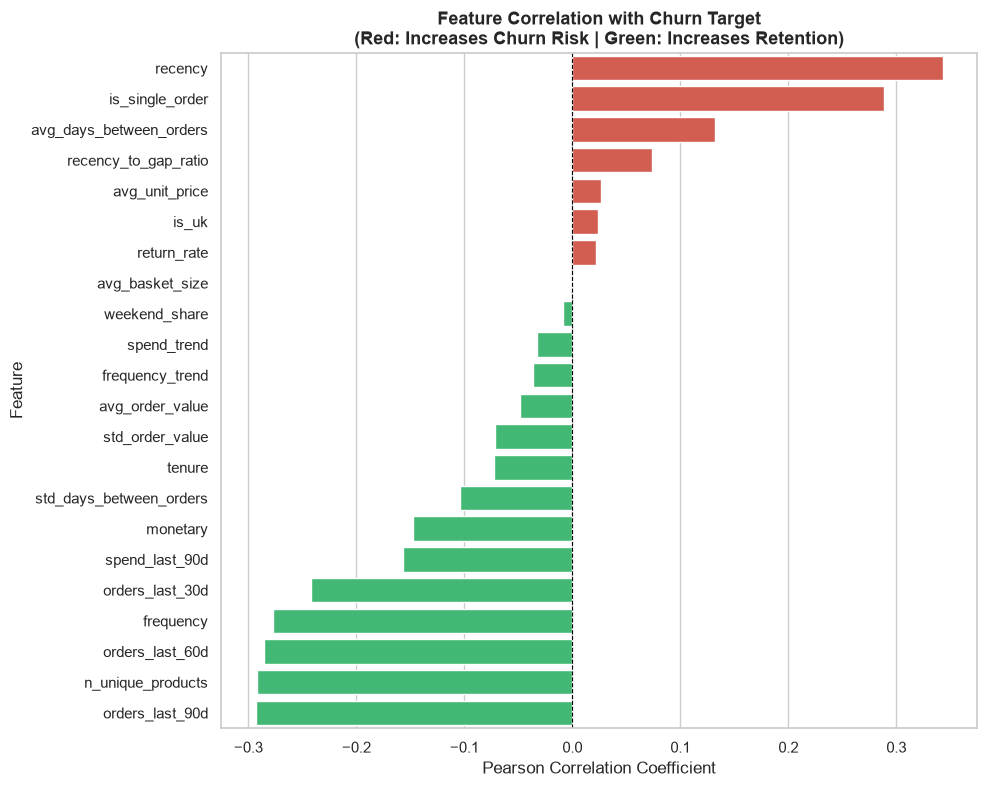

>> AUDIT FINDING: Maximum correlation is only +0.3428 (recency) and -0.2932 (orders_last_90d).
>> VERDICT: ZERO DIRECT DATA LEAKAGE detected! Features represent pre-snapshot behavior, while label reflects post-snapshot outcome.


In [4]:
print("="*60)
print("1. Target (churn) Distribution:")
churn_dist = pd.DataFrame({
    'Count': df['churn'].value_counts(),
    'Percentage (%)': df['churn'].value_counts(normalize=True) * 100
})
display(churn_dist)

print("\n" + "="*60)
print("2. Split Strategy and Snapshot Mapping:")
snap_split = pd.crosstab(df['snapshot'], df['split'], margins=True)
display(snap_split)

print("\n" + "="*60)
print("3. Pearson Correlation with Target (Data Leakage Audit):")
corr_target = df[list(num_cols) + ['is_uk', 'is_single_order']].apply(lambda x: x.corr(df['churn'])).sort_values()
corr_df = pd.DataFrame({'Feature': corr_target.index, 'Correlation': corr_target.values}).sort_values(by='Correlation', ascending=False)
display(corr_df)

# Plotting correlation bar chart
plt.figure(figsize=(10, 8))
bar_colors = ['#e74c3c' if val > 0 else '#2ecc71' for val in corr_df['Correlation']]
sns.barplot(data=corr_df, x='Correlation', y='Feature', palette=bar_colors)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('Feature Correlation with Churn Target\n(Red: Increases Churn Risk | Green: Increases Retention)', fontsize=13, fontweight='bold')
plt.xlabel('Pearson Correlation Coefficient')
plt.tight_layout()
os.makedirs('reports/figures', exist_ok=True)
plt.savefig('reports/figures/01_feature_correlation_with_churn.png', dpi=300)
plt.show()

print(">> AUDIT FINDING: Maximum correlation is only +0.3428 (recency) and -0.2932 (orders_last_90d).")
print(">> VERDICT: ZERO DIRECT DATA LEAKAGE detected! Features represent pre-snapshot behavior, while label reflects post-snapshot outcome.")


### 6. Exploratory Data Analysis (EDA) - Deep Behavioral Insights
نستكشف هنا أنماط سلوك العملاء عبر الرسومات البيانية:
1. الفروق في `recency` و`tenure` بين العملاء المغادرين والمستمرين.
2. مقارنة القيمة المالية (`monetary`) وتكرار الطلبات (`frequency`) مع تمثيل Log-scale للتعامل مع الـ Outliers.
3. مصفوفة الارتباط بين أهم الخصائص السلوكية (Correlation Heatmap).


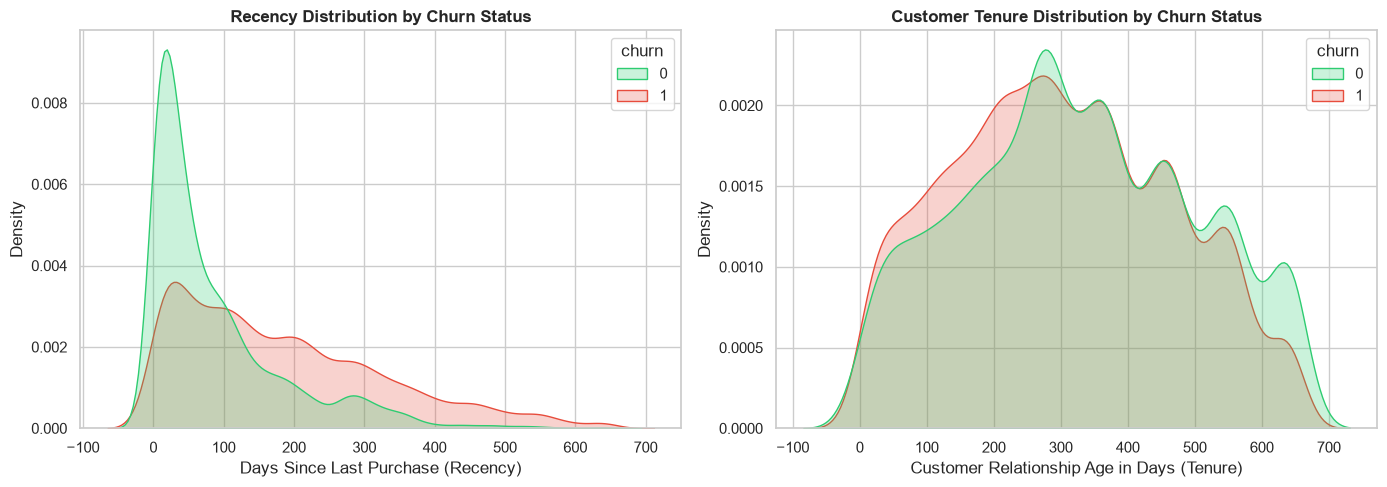

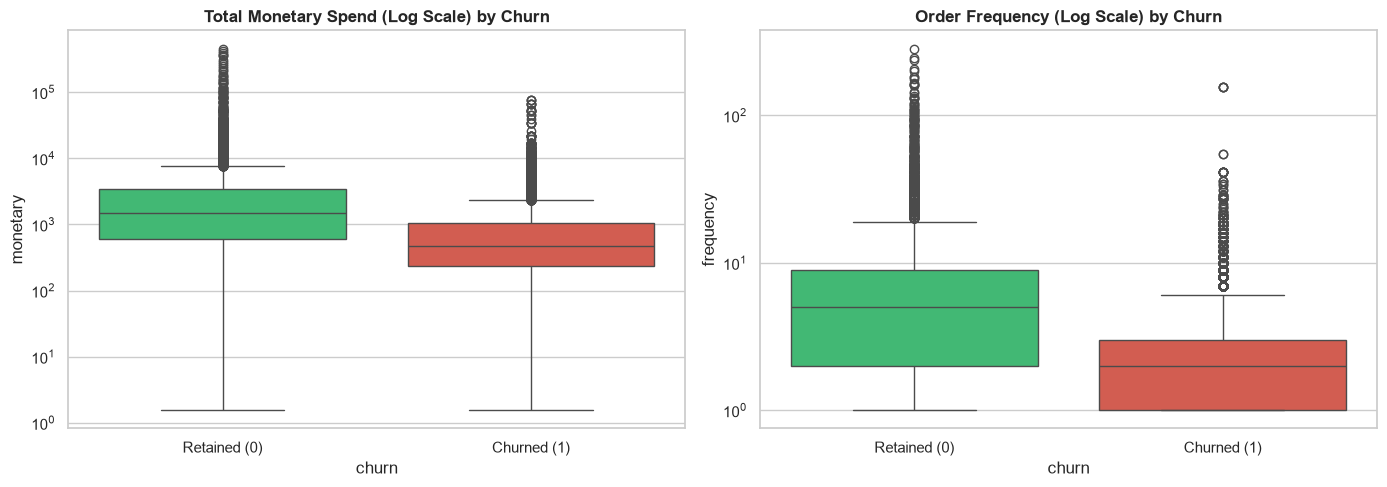

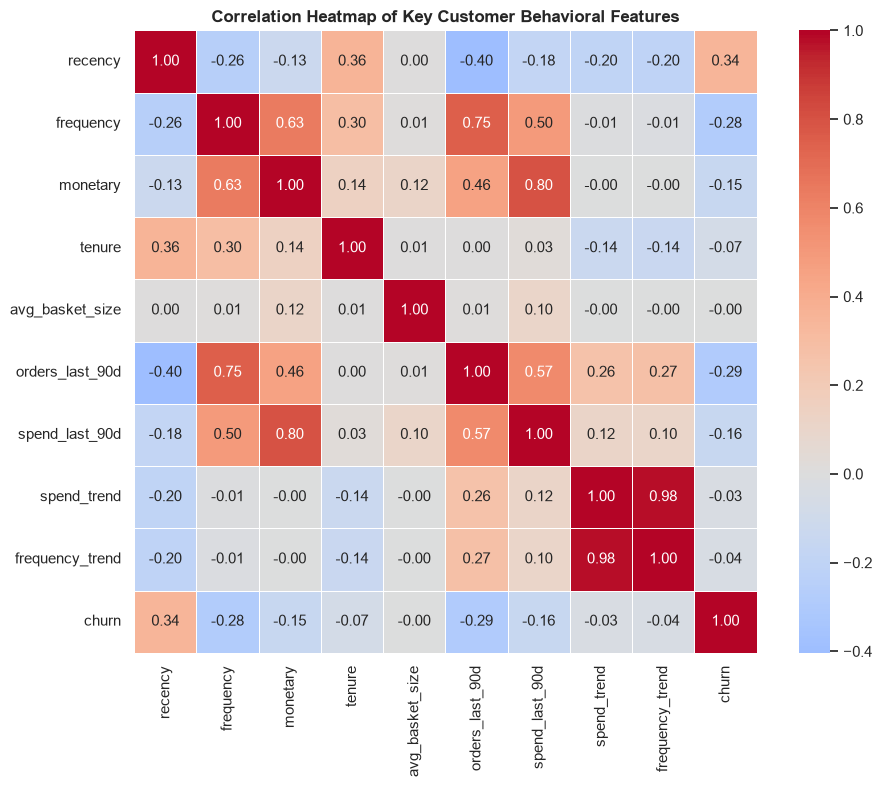

In [5]:
# 1. Recency & Tenure distributions by Churn
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.kdeplot(data=df, x='recency', hue='churn', common_norm=False, fill=True, ax=axes[0], palette=['#2ecc71', '#e74c3c'])
axes[0].set_title('Recency Distribution by Churn Status', fontweight='bold')
axes[0].set_xlabel('Days Since Last Purchase (Recency)')

sns.kdeplot(data=df, x='tenure', hue='churn', common_norm=False, fill=True, ax=axes[1], palette=['#2ecc71', '#e74c3c'])
axes[1].set_title('Customer Tenure Distribution by Churn Status', fontweight='bold')
axes[1].set_xlabel('Customer Relationship Age in Days (Tenure)')
plt.tight_layout()
plt.savefig('reports/figures/02_recency_tenure_by_churn.png', dpi=300)
plt.show()

# 2. Monetary & Frequency (Boxplots with log scale)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x='churn', y='monetary', ax=axes[0], palette=['#2ecc71', '#e74c3c'])
axes[0].set_yscale('log')
axes[0].set_title('Total Monetary Spend (Log Scale) by Churn', fontweight='bold')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Retained (0)', 'Churned (1)'])

sns.boxplot(data=df, x='churn', y='frequency', ax=axes[1], palette=['#2ecc71', '#e74c3c'])
axes[1].set_yscale('log')
axes[1].set_title('Order Frequency (Log Scale) by Churn', fontweight='bold')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Retained (0)', 'Churned (1)'])
plt.tight_layout()
plt.savefig('reports/figures/03_monetary_frequency_by_churn.png', dpi=300)
plt.show()

# 3. Behavioral Correlation Heatmap
key_features = ['recency', 'frequency', 'monetary', 'tenure', 'avg_basket_size', 
                'orders_last_90d', 'spend_last_90d', 'spend_trend', 'frequency_trend', 'churn']
plt.figure(figsize=(10, 8))
corr_matrix = df[key_features].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, linewidths=0.5)
plt.title('Correlation Heatmap of Key Customer Behavioral Features', fontweight='bold')
plt.tight_layout()
plt.savefig('reports/figures/04_behavioral_correlation_heatmap.png', dpi=300)
plt.show()


### 7. Feature Architecture & Data Dictionary
تصنيف الأعمدة وفصل معرّفات العميل والوقت عن مصفوفة المتغيرات التنبؤية (Feature Matrix $X$).
وإنشاء Data Dictionary متكامل يشرح كل عمود ونوعه ووظيفته ونطاق قيمه.


In [6]:
# 1. Column Role Separation
id_cols = ['Customer ID']
temporal_meta_cols = ['snapshot', 'split']
target_col = 'churn'

model_features = [c for c in df.columns if c not in id_cols + temporal_meta_cols + [target_col]]
continuous_features = [c for c in model_features if c not in ['is_uk', 'is_single_order']]
binary_features = ['is_uk', 'is_single_order']

print(f"Total Columns in Raw Data: {df.shape[1]}")
print(f"- Identifier Columns (Exclude from X): {id_cols}")
print(f"- Metadata / Split Columns: {temporal_meta_cols}")
print(f"- Target Column: {target_col}")
print(f"- Predictive Model Features (Total: {len(model_features)}):")
print(f"    * Continuous Numerical ({len(continuous_features)}): {continuous_features}")
print(f"    * Binary Categorical ({len(binary_features)}): {binary_features}")

# 2. Build Comprehensive Data Dictionary
dict_records = []
for col in df.columns:
    if col in id_cols:
        role = 'Identifier'
    elif col in temporal_meta_cols:
        role = 'Temporal Metadata'
    elif col == target_col:
        role = 'Target (Label)'
    elif col in binary_features:
        role = 'Binary Feature'
    else:
        role = 'Continuous Feature'
        
    dtype_str = str(df[col].dtype)
    val_range = f"[{df[col].min():.2f} to {df[col].max():.2f}]" if pd.api.types.is_numeric_dtype(df[col]) else f"{df[col].nunique()} unique"
    
    meanings = {
        'Customer ID': 'Unique customer identifier from Online Retail II',
        'snapshot': 'Quarterly observation date (t) at which features are computed',
        'split': 'Pre-assigned split indicator (train / test)',
        'recency': 'Days elapsed since customer last purchase prior to snapshot date',
        'frequency': 'Total number of valid historical orders prior to snapshot date',
        'monetary': 'Total monetary value spent by customer prior to snapshot date',
        'avg_order_value': 'Average spend per purchase transaction',
        'std_order_value': 'Standard deviation of order values (0 for single orders)',
        'tenure': 'Days elapsed since customer first observed purchase',
        'avg_days_between_orders': 'Average gap in days between consecutive orders',
        'std_days_between_orders': 'Standard deviation of order intervals',
        'recency_to_gap_ratio': 'Ratio of current recency to average inter-purchase gap',
        'is_single_order': 'Binary flag: 1 if customer made only 1 order historically, else 0',
        'n_unique_products': 'Count of distinct product stock codes purchased',
        'avg_basket_size': 'Average number of product units per order',
        'avg_unit_price': 'Average price per unit across purchased items',
        'return_rate': 'Proportion of returned/cancelled items relative to total units',
        'orders_last_30d': 'Number of purchases made in the 30 days prior to snapshot',
        'orders_last_60d': 'Number of purchases made in the 60 days prior to snapshot',
        'orders_last_90d': 'Number of purchases made in the 90 days prior to snapshot',
        'spend_last_90d': 'Monetary spend in the 90 days prior to snapshot',
        'spend_trend': 'Directional trend in spending (recent vs historical)',
        'frequency_trend': 'Directional trend in order frequency (recent vs historical)',
        'is_uk': 'Binary flag: 1 if customer resides in the UK, else 0',
        'weekend_share': 'Fraction of orders placed on Saturday or Sunday',
        'churn': 'Target: 1 if zero orders in subsequent 90 days, else 0'
    }
    
    dict_records.append({
        'Feature_Name': col,
        'Role': role,
        'Data_Type': dtype_str,
        'Value_Range': val_range,
        'Description': meanings.get(col, 'N/A')
    })

data_dict_df = pd.DataFrame(dict_records)
data_dict_df.to_csv('data_dictionary.csv', index=False)
print("\n>> Generated and saved 'data_dictionary.csv' successfully!")
display(data_dict_df)


Total Columns in Raw Data: 26
- Identifier Columns (Exclude from X): ['Customer ID']
- Metadata / Split Columns: ['snapshot', 'split']
- Target Column: churn
- Predictive Model Features (Total: 22):
    * Continuous Numerical (20): ['recency', 'frequency', 'monetary', 'avg_order_value', 'std_order_value', 'tenure', 'avg_days_between_orders', 'std_days_between_orders', 'recency_to_gap_ratio', 'n_unique_products', 'avg_basket_size', 'avg_unit_price', 'return_rate', 'orders_last_30d', 'orders_last_60d', 'orders_last_90d', 'spend_last_90d', 'spend_trend', 'frequency_trend', 'weekend_share']
    * Binary Categorical (2): ['is_uk', 'is_single_order']

>> Generated and saved 'data_dictionary.csv' successfully!


,Feature_Name,Role,Data_Type,Value_Range,Description
0,Customer ID,Identifier,int64,[12346.00 to 18287.00],Unique customer identifier from Online Retail II
1,snapshot,Temporal Metadata,str,5 unique,Quarterly observation date (t) at which featur...
2,split,Temporal Metadata,str,2 unique,Pre-assigned split indicator (train / test)
3,recency,Continuous Feature,float64,[0.17 to 646.55],Days elapsed since customer last purchase prio...
4,frequency,Continuous Feature,int64,[1.00 to 284.00],Total number of valid historical orders prior ...
5,monetary,Continuous Feature,float64,[1.55 to 456780.49],Total monetary value spent by customer prior t...
6,avg_order_value,Continuous Feature,float64,[1.55 to 25784.32],Average spend per purchase transaction
7,std_order_value,Continuous Feature,float64,[0.00 to 44513.12],Standard deviation of order values (0 for sing...
8,tenure,Continuous Feature,float64,[0.30 to 646.68],Days elapsed since customer first observed pur...
9,avg_days_between_orders,Continuous Feature,float64,[0.00 to 632.12],Average gap in days between consecutive orders


### 8. Temporal Train / Validation / Test Splitting
في بيانات السلاسل الزمنية واللقطات الطولية (Panel Data)، التقسيم العشوائي (Random Split) يسبب تسريب كارثي (Data Leakage) لأن نفس العميل سيظهر في الـ Train والـ Test في نفس التوقيت أو أوقات لاحقة.
لذا نعتمد **Out-Of-Time Temporal Split**:
- **Train Set (Snapshots 1, 2, 3):** من سبتمبر 2010 حتى مارس 2011 (12,178 سجل - 54.4%).
- **Validation Set (Snapshot 4):** يونيو 2011 (4,941 سجل - 22.1%) لضبط الـ Hyperparameters واختيار النماذج بدون لمس الـ Test.
- **Holdout Test Set (Snapshot 5):** سبتمبر 2011 (5,253 سجل - 23.5%) للتقييم النهائي الصارم.


In [7]:
# 1. Temporal Split Partitioning
train_mask = df['snapshot'].isin(['2010-09-09', '2010-12-09', '2011-03-09'])
val_mask = df['snapshot'] == '2011-06-09'
test_mask = df['snapshot'] == '2011-09-09'

df_train = df[train_mask].copy()
df_val = df[val_mask].copy()
df_test = df[test_mask].copy()

# Add partition column for convenient single-file usage
df['partition'] = 'train'
df.loc[val_mask, 'partition'] = 'val'
df.loc[test_mask, 'partition'] = 'test'

print("="*60)
print("Temporal Partition Summary:")
split_summary = pd.DataFrame({
    'Partition': ['Train (Snapshots 1-3)', 'Validation (Snapshot 4)', 'Holdout Test (Snapshot 5)', 'Total'],
    'Snapshots Included': ['2010-09-09, 2010-12-09, 2011-03-09', '2011-06-09', '2011-09-09', 'All 5 Snapshots'],
    'Row Count': [len(df_train), len(df_val), len(df_test), len(df)],
    'Share (%)': [len(df_train)/len(df)*100, len(df_val)/len(df)*100, len(df_test)/len(df)*100, 100.0],
    'Churn Rate (%)': [df_train['churn'].mean()*100, df_val['churn'].mean()*100, df_test['churn'].mean()*100, df['churn'].mean()*100]
})
display(split_summary)


Temporal Partition Summary:


,Partition,Snapshots Included,Row Count,Share (%),Churn Rate (%)
0,Train (Snapshots 1-3),"2010-09-09, 2010-12-09, 2011-03-09",12178,54.4341,60.1905
1,Validation (Snapshot 4),2011-06-09,4941,22.0856,67.6584
2,Holdout Test (Snapshot 5),2011-09-09,5253,23.4802,56.6343
3,Total,All 5 Snapshots,22372,100.0000,61.0048


### 9. Scikit-Learn Preprocessing Pipeline (Leakage-Free)
نظراً لوجود التواء شديد وقيم شاذة ضخمة في متغيرات زي `monetary` و`avg_basket_size`، نستخدم **RobustScaler** (المبني على الوسيط والـ Interquartile Range) للمتغيرات المتصلة، مع ترك المتغيرات الثنائية (`is_uk`, `is_single_order`) كما هي عبر `passthrough`.
**القاعدة الذهبية:** يتم تدريب الـ Preprocessor حصرياً على بيانات الـ Train (`fit` on train only)، ثم تطبيقه على الـ Val والـ Test لتجنب أي تسريب إحصائي.


In [8]:
# 1. Define ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num_scaler', RobustScaler(), continuous_features),
        ('binary_pass', 'passthrough', binary_features)
    ],
    remainder='drop'
)

# 2. Fit strictly on X_train
X_train_raw = df_train[model_features]
y_train = df_train[target_col]

X_val_raw = df_val[model_features]
y_val = df_val[target_col]

X_test_raw = df_test[model_features]
y_test = df_test[target_col]

# Full train (snapshots 1 to 4) for final model refitting if needed
df_full_train = df[df['split'] == 'train'].copy()
X_full_train_raw = df_full_train[model_features]
y_full_train = df_full_train[target_col]

# Fit preprocessor
preprocessor.fit(X_train_raw)

# 3. Transform sets
transformed_cols = continuous_features + binary_features
X_train_proc = pd.DataFrame(preprocessor.transform(X_train_raw), columns=transformed_cols, index=df_train.index)
X_val_proc = pd.DataFrame(preprocessor.transform(X_val_raw), columns=transformed_cols, index=df_val.index)
X_test_proc = pd.DataFrame(preprocessor.transform(X_test_raw), columns=transformed_cols, index=df_test.index)

# 4. Save fitted preprocessor
os.makedirs('models', exist_ok=True)
joblib.dump(preprocessor, 'models/preprocessor_robust.joblib')
print(">> Fitted RobustScaler Pipeline on Train data and saved to 'models/preprocessor_robust.joblib' successfully!")
display(X_train_proc.head(3))


>> Fitted RobustScaler Pipeline on Train data and saved to 'models/preprocessor_robust.joblib' successfully!


,recency,frequency,monetary,avg_order_value,std_order_value,tenure,avg_days_between_orders,std_days_between_orders,recency_to_gap_ratio,n_unique_products,avg_basket_size,avg_unit_price,return_rate,orders_last_30d,orders_last_60d,orders_last_90d,spend_last_90d,spend_trend,frequency_trend,weekend_share,is_uk,is_single_order
0,-0.0832,0.0000,-0.3656,-0.8234,0.1329,-0.2816,2.5005,0.0000,-0.2657,-0.2131,-0.8154,2.7227,0.0000,0.0000,0.0000,0.0000,0.0907,0.6368,0.6667,0.0000,1.0000,0.0000
1,0.3676,-0.2500,0.3001,3.2443,-0.3689,-0.5686,-0.2144,0.0000,0.4868,0.1475,1.8981,0.8699,1.5134,0.0000,0.0000,-1.0000,-0.2176,-0.6368,-0.6667,0.0000,0.0000,1.0000
2,0.2028,-0.2500,-0.1295,0.8450,-0.3689,-0.6772,-0.2144,0.0000,0.3274,-0.2459,0.8975,-0.3302,0.0000,0.0000,0.0000,-1.0000,-0.2176,-0.6368,-0.6667,0.0000,0.0000,1.0000


### 10. Artifact Export & Modeler Handoff
حفظ ملفات البيانات المنقاة والمقسمة داخل مجلد `data/processed/` ومجلد المشروع، لتمكين مطور النماذج من البدء الفوري في تدريب خوارزميات التصنيف الخمسة المطلوبة (Logistic Regression, Decision Tree, KNN, SVM, Gradient Boosting).


In [9]:
os.makedirs('data/processed', exist_ok=True)

# 1. Export Clean Raw Split Datasets (with IDs, Metadata, Features, Target)
df_train.to_csv('data/processed/train.csv', index=False)
df_val.to_csv('data/processed/val.csv', index=False)
df_test.to_csv('data/processed/test.csv', index=False)
df_full_train.to_csv('data/processed/full_train.csv', index=False)

# Also save directly in root directory for maximum convenience
df_train.to_csv('train.csv', index=False)
df_val.to_csv('val.csv', index=False)
df_test.to_csv('test.csv', index=False)

# 2. Export Scaled Feature Sets
X_train_proc.assign(churn=y_train.values).to_csv('data/processed/train_scaled.csv', index=False)
X_val_proc.assign(churn=y_val.values).to_csv('data/processed/val_scaled.csv', index=False)
X_test_proc.assign(churn=y_test.values).to_csv('data/processed/test_scaled.csv', index=False)

print("="*60)
print("SUCCESS: All datasets successfully prepared and exported!")
print("- data/processed/train.csv & train.csv :", df_train.shape)
print("- data/processed/val.csv & val.csv     :", df_val.shape)
print("- data/processed/test.csv & test.csv   :", df_test.shape)
print("- data/processed/train_scaled.csv       :", X_train_proc.shape)
print("- models/preprocessor_robust.joblib    : Fitted Preprocessing Pipeline")
print("- data_dictionary.csv                   : Complete 26-column reference")
print("="*60)


SUCCESS: All datasets successfully prepared and exported!
- data/processed/train.csv & train.csv : (12178, 26)
- data/processed/val.csv & val.csv     : (4941, 26)
- data/processed/test.csv & test.csv   : (5253, 26)
- data/processed/train_scaled.csv       : (12178, 22)
- models/preprocessor_robust.joblib    : Fitted Preprocessing Pipeline
- data_dictionary.csv                   : Complete 26-column reference


### 11. Final Recommendations for the Modeling Engineer
* **Model Algorithms Required:**
  1. Logistic Regression
  2. Decision Tree
  3. K-Nearest Neighbors (KNN)
  4. Support Vector Machine (SVM)
  5. Gradient Boosting (XGBoost / LightGBM / GradientBoostingClassifier)
* **Evaluation Strategy & Metrics:**
  - نظراً لأن تكلفة خسارة العميل (False Negative) أعلى بكثير من تقديم عرض لعميل مستمر (False Positive)، نوصي بالتركيز على: **Recall (Class 1)** و **PR-AUC / F1-Score** و **ROC-AUC**، بدلاً من الاعتماد الأعمى على الـ Accuracy وحدها.
* **Class Imbalance Handling:**
  - نسبة الـ Churn في Train حوالي 59-67%. نوصي بتفعيل `class_weight='balanced'` في Logistic Regression وSVM وDecision Tree.
* **Feature Scaling:**
  - للنماذج المعتمدة على المسافات والانحدار الخطي (KNN, SVM, Logistic Regression): استخدم الملفات المعالجة `train_scaled.csv` أو طبّق `models/preprocessor_robust.joblib`.
  - للنماذج الشجرية (Decision Tree, Gradient Boosting): لا تتأثر بالـ Scaling ويمكن تدريبها مباشرة على `train.csv`.
* **Cross-Validation:**
  - عند عمل Hyperparameter Tuning، استخدم `TimeSeriesSplit` أو `GroupKFold(groups=Customer ID)` لتفادي تكرار بيانات نفس العميل بين الـ Folds.
